# A_v2 — Albopictus D5 cho train và validation

**Câu hỏi:** bốn loài có được phân biệt trên các clip chưa học khi albopictus train/validation cùng domain D5 không?

Notebook kế thừa QC, pool audio và các nhóm liên quan đã phát hiện ở A_v1; chỉ thay cách chia albopictus. Không thu thêm dữ liệu, không đổi nhãn và không xuất WAV nhỏ.

- Ba loài còn lại và tập test giữ cách chia A_v1.
- Chia D5 theo nhóm đã biết, trước khi gán split cho window; mọi window của một clip luôn cùng tập.
- Albopictus D1 chuyển sang `diagnostic`, không dùng huấn luyện, chuẩn hóa, early stopping hoặc chọn tham số trong A_v2.
- D5 thiếu metadata cá thể/phiên thu: chia theo clip chưa chứng minh độc lập cá thể. D5 chỉ gắn với albopictus nên vẫn có thể học đặc điểm nguồn thu. Điểm cao không chứng minh chuyển được sang INMP441.
- Kết quả 05–06 và A_v1 là bằng chứng thất bại chuyển nguồn, được giữ riêng. A_v2 không sửa kết quả lịch sử đó.

## 0. Chuẩn bị môi trường và dữ liệu dùng chung
Local đọc dữ liệu hiện có. Colab dùng `A_v1_bundle.zip` trên shortcut Drive như trước để lấy audio và audit A_v1. Không cần upload lại WAV. Phần A không huấn luyện model và không cần GPU.

In [1]:
from pathlib import Path, PureWindowsPath, PurePosixPath
import os, sys, subprocess, shutil, csv, hashlib, io, json, re, time, zipfile
import importlib.util, importlib.metadata
EXECUTION_ENV='auto'  # auto / local / colab
DRIVE_FOLDER=Path('/content/drive/MyDrive/Edge_AI_Mosquito')
COLAB_PROJECT_DIR=Path('/content/Edge_AI_Mosquito')
REPO_URL='https://github.com/ancaranovik/Edge_AI_Mosquito.git'
REPO_BRANCH='main'
BUNDLE_SHA256='29a099018450a1dc1e54201c58d441a72d53ec0c8ace10b8921b40c4c34c6278'
PROTOCOL_VERSION='A_v2'
SEED=42
VALIDATION_GROUP_FRACTION=0.20
SAMPLE_RATE=8000
WINDOW_SAMPLES=2400
HOP_SAMPLES=1200
assert EXECUTION_ENV in ('auto','local','colab') and 0<VALIDATION_GROUP_FRACTION<1
try:has_colab=importlib.util.find_spec('google.colab') is not None
except ModuleNotFoundError:has_colab=False
IS_COLAB=EXECUTION_ENV=='colab' or (EXECUTION_ENV=='auto' and has_colab and Path('/content').is_dir())
print('Môi trường:', 'Colab' if IS_COLAB else 'local')

Môi trường: local


In [2]:
def bootstrap_sha(path):
    with Path(path).open('rb') as f: return hashlib.file_digest(f,'sha256').hexdigest()

def archive_relative(name):
    rel=PurePosixPath(name)
    if not name or rel.is_absolute() or '..' in rel.parts or chr(92) in name or ':' in name:
        raise ValueError('Đường dẫn archive không hợp lệ: '+name)
    return rel

def extract_dataset_bundle(archive,project_root):
    project_root=Path(project_root).resolve()
    with zipfile.ZipFile(archive) as z:
        names=z.namelist()
        assert len(names)==len(set(names)), 'Archive trùng tên file'
        for name in names: archive_relative(name)
        rows=list(csv.DictReader(io.StringIO(z.read('bundle_inventory.csv').decode('utf-8-sig'))))
        selected=[r for r in rows if r['archive_path'].startswith(('data/','results/A/'))]
        assert len({r['archive_path'] for r in selected})==len(selected)
        assert {n for n in names if n.startswith(('data/','results/A/'))}=={r['archive_path'] for r in selected}
        assert sum(r['type']=='audio' for r in selected)==2905
        needed=sum(int(r['bytes']) for r in selected if not project_root.joinpath(*archive_relative(r['archive_path']).parts).exists())
        if shutil.disk_usage(project_root).free < needed+100_000_000:
            raise OSError('Ổ tạm không đủ chỗ giải nén gói A_v1')
        reused=written=0
        for i,row in enumerate(selected,1):
            rel=archive_relative(row['archive_path']);target=project_root.joinpath(*rel.parts)
            assert target.resolve().is_relative_to(project_root)
            if target.is_file() and target.stat().st_size==int(row['bytes']) and bootstrap_sha(target)==row['sha256']:
                reused+=1;continue
            target.parent.mkdir(parents=True,exist_ok=True)
            tmp=target.with_name(target.name+'.extracting')
            h=hashlib.sha256();size=0
            with z.open(row['archive_path']) as src,tmp.open('wb') as dst:
                while chunk:=src.read(1024*1024): dst.write(chunk);h.update(chunk);size+=len(chunk)
            if h.hexdigest()!=row['sha256'] or size!=int(row['bytes']):
                raise ValueError('Hash giải nén sai: '+str(rel))
            os.replace(tmp,target);written+=1
            if i%500==0: print('Giải nén/kiểm tra:',i,'/',len(selected),flush=True)
    return dict(bundle_files=len(selected),audio_files=2905,files_written=written,files_reused=reused)

bootstrap_info=dict(environment='colab' if IS_COLAB else 'local',bundle_sha256='not_used')
if IS_COLAB:
    if not Path('/content/drive/MyDrive').is_dir():
        from google.colab import drive
        drive.mount('/content/drive')
    source_bundle=DRIVE_FOLDER/'A_v1_bundle.zip'
    if not source_bundle.is_file():
        raise FileNotFoundError(f'Không thấy {source_bundle}. Kiểm tra tên shortcut trong My Drive A.')
    ROOT=COLAB_PROJECT_DIR.resolve()
    if not (ROOT/'.git').exists():
        if ROOT.exists() and any(ROOT.iterdir()):
            raise RuntimeError('Folder Colab đã có file nhưng chưa có Git; chọn COLAB_PROJECT_DIR khác.')
        subprocess.run(['git','clone','--branch',REPO_BRANCH,REPO_URL,str(ROOT)],check=True)
    else:
        remote=subprocess.check_output(['git','-C',str(ROOT),'remote','get-url','origin'],text=True).strip()
        assert remote.rstrip('/').removesuffix('.git')==REPO_URL.rstrip('/').removesuffix('.git')
        dirty=subprocess.check_output(['git','-C',str(ROOT),'status','--porcelain','--untracked-files=no'],text=True)
        if dirty.strip(): raise RuntimeError('Code trên runtime đã sửa. Giữ bản sửa trước khi pull; không tự reset.')
        branch=subprocess.check_output(['git','-C',str(ROOT),'branch','--show-current'],text=True).strip()
        assert branch==REPO_BRANCH,'Checkout branch khác; không tự đổi hoặc ghi đè.'
        subprocess.run(['git','-C',str(ROOT),'pull','--ff-only','origin',REPO_BRANCH],check=True)
    staging=ROOT/'data/.bundle';staging.mkdir(parents=True,exist_ok=True)
    local_bundle=staging/'A_v1_bundle.zip'
    if not local_bundle.is_file() or bootstrap_sha(local_bundle)!=BUNDLE_SHA256:
        if shutil.disk_usage(ROOT).free < source_bundle.stat().st_size+100_000_000:
            raise OSError('Ổ tạm không đủ chỗ copy archive')
        tmp=local_bundle.with_suffix('.zip.copying')
        shutil.copyfile(source_bundle,tmp)
        assert bootstrap_sha(tmp)==BUNDLE_SHA256,'Archive trên Drive chưa khớp gói A_v1 đã chốt'
        os.replace(tmp,local_bundle)
    bootstrap_info.update(extract_dataset_bundle(local_bundle,ROOT),bundle_sha256=BUNDLE_SHA256)
    os.chdir(ROOT)
else:
    ROOT=next((p for p in [Path.cwd(),*Path.cwd().parents] if (p/'notebooks').is_dir() and (p/'README.md').is_file()),None)
    if ROOT is None: raise FileNotFoundError('Mở notebook từ folder repo local.')
    ROOT=ROOT.resolve()
try:
    bootstrap_info['git_commit']=subprocess.check_output(['git','-C',str(ROOT),'rev-parse','HEAD'],text=True,stderr=subprocess.DEVNULL).strip()
except subprocess.CalledProcessError:
    bootstrap_info['git_commit']='not_available'
print('Project trên kernel:',ROOT)
print(bootstrap_info)

Project trên kernel: D:\VGU-27\Edge AI Rebuild
{'environment': 'local', 'bundle_sha256': 'not_used', 'git_commit': '26ceb4e27baba1816c1c7c4011acb513fd0b246b'}


In [3]:
packages={'numpy':'numpy','pandas':'pandas','scipy':'scipy','soundfile':'soundfile','matplotlib':'matplotlib','seaborn':'seaborn','nbformat':'nbformat'}
missing=[p for p,module in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    if not IS_COLAB:raise RuntimeError('Cài thư viện từ requirements.txt trong môi trường local: '+', '.join(missing))
    subprocess.run([sys.executable,'-m','pip','install',*missing],check=True)

## 1. Kiểm tra A_v1 và khóa nguồn đầu vào
Kiểm checksum bản chốt A_v1 trước khi chia lại. Chỉ vị trí notebook A_v1 thay đổi khi tổ chức folder; verifier kiểm cả cách viết đường dẫn lịch sử, không bỏ qua thay đổi thuật toán. Các file audit và manifest A_v1 được giữ nguyên.

In [4]:
import nbformat
import numpy as np
import pandas as pd
import soundfile as sf
import scipy
from scipy.signal import resample_poly
from math import gcd, ceil
from datetime import datetime
from zoneinfo import ZoneInfo
import html, base64
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
NOTEBOOK_PATH=ROOT/'notebooks/A_v2/03_A_data_preparation.ipynb'
notebook_source=nbformat.read(NOTEBOOK_PATH,as_version=4)
core_cells={c.metadata.tags[0]:c.source for c in notebook_source.cells if c.cell_type=='code' and c.metadata.get('tags') and c.metadata.tags[0] not in ('settings','bootstrap','dependencies')}
def verify_cell(tag):
    from IPython import get_ipython
    shell=get_ipython()
    if shell is not None and shell.history_manager.input_hist_raw:
        assert shell.history_manager.input_hist_raw[-1].replace('\r\n','\n').strip()==core_cells[tag].replace('\r\n','\n').strip(), 'Cell khác source repo: '+tag
def sha(path):
    with Path(path).open('rb') as f:return hashlib.file_digest(f,'sha256').hexdigest()
def frozen_path(value):
    rel=PureWindowsPath(str(value))
    assert not rel.is_absolute() and not rel.drive and '..' not in rel.parts
    return ROOT.joinpath(*rel.parts)
PARENT_CLIPS=ROOT/'data/manifests/biodcase_four_species_clips.csv'
PARENT_WINDOWS=ROOT/'data/manifests/biodcase_four_species_windows.csv'
PARENT_FREEZE=ROOT/'results/A/preparation/tables/dataset_freeze.csv'
PARENT_NOTEBOOK=ROOT/'notebooks/A_v1/03_A_data_preparation.ipynb'
parent_freeze=pd.read_csv(PARENT_FREEZE,keep_default_na=False).set_index('item').value.to_dict()
assert parent_freeze['protocol_version']=='A_v1'
parent_source='\n'.join(c.source for c in nbformat.read(PARENT_NOTEBOOK,as_version=4).cells)
parent_historical=parent_source.replace('notebooks/A_v1/03_A_data_preparation.ipynb','notebooks/03_A_data_preparation.ipynb')
assert parent_freeze['notebook_source_sha256'] in {hashlib.sha256(t.encode()).hexdigest() for t in [parent_source,parent_historical]}
for key,value in parent_freeze.items():
    if key.endswith('_path'):assert sha(frozen_path(value))==parent_freeze[key[:-5]+'_sha256'],key
parent_clips=pd.read_csv(PARENT_CLIPS,keep_default_na=False)
parent_windows=pd.read_csv(PARENT_WINDOWS,keep_default_na=False)
near_path=frozen_path(parent_freeze['near_pairs_path'])
near_pairs=pd.read_csv(near_path,keep_default_na=False)
assert near_pairs.strong_link.isin([True,False]).all()
strong_pairs=near_pairs.loc[near_pairs.strong_link.eq(True)].copy()
PROTECTED={p:sha(p) for p in [PARENT_CLIPS,PARENT_WINDOWS,PARENT_FREEZE,PARENT_NOTEBOOK,near_path]}
OUT=ROOT/'results/A_v2/preparation'
TABLES,FIGURES=OUT/'tables',OUT/'figures'
MANIFESTS=ROOT/'data/manifests/A_v2'
CLIP_PATH=MANIFESTS/'biodcase_four_species_clips.csv'
WINDOW_PATH=MANIFESTS/'biodcase_four_species_windows.csv'
FREEZE_PATH=TABLES/'dataset_freeze.csv'
for folder in [TABLES,FIGURES,MANIFESTS]:folder.mkdir(parents=True,exist_ok=True)
def table(frame,name):
    frame.to_csv(TABLES/(name+'.csv'),index=False,encoding='utf-8-sig');return frame
def figure(name):
    plt.tight_layout();plt.savefig(FIGURES/(name+'.png'),dpi=150,bbox_inches='tight');plt.show();plt.close()
checks=[]
def check(name,condition):
    checks.append(dict(check=name,passed=bool(condition)));assert condition,name
LABEL_NAMES=['Aedes aegypti','Aedes albopictus','Anopheles dirus','Anopheles minimus']
SPLITS=['train','validation','diagnostic','test']
sns.set_theme(style='whitegrid');plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
verify_cell('parent_audit')
check('Checksum A_v1 hợp lệ',True)
print('Pool kế thừa:',len(parent_clips),'clip;',len(parent_windows),'window')

Pool kế thừa: 2905 clip; 113477 window


## 2. Chia albopictus D5 theo nhóm đã phát hiện
Giữ nguyên 1.374 clip D5 đã chọn của A_v1, không lấy thêm từ raw data. Chọn khoảng 20% **nhóm** cho validation bằng seed cố định; tỷ lệ clip có thể lệch nếu nhóm nhiều clip. Không chia window ngẫu nhiên. Nhóm D5 hiện mang bằng chứng `unverified_clip`; không biến ID clip thành ID phiên thu đã xác minh.

In [5]:
verify_cell('split')
clips=parent_clips.copy(deep=True)
kept_parent=clips.loc[clips.status.eq('keep')].copy()
d5=kept_parent.loc[kept_parent.label_id.eq(1)&kept_parent.domain.eq('D5')].copy()
check('D5 là pool train albopictus của A_v1',len(d5)>1 and d5.split.eq('train').all() and d5.window_eligible.all())
groups=sorted(d5.leakage_group.unique())
check('D5 có ít nhất hai nhóm',len(groups)>1 and all(groups))
check('Nhóm D5 không liên kết domain hoặc loài khác',set(kept_parent.loc[kept_parent.leakage_group.isin(groups),'clip_id'])==set(d5.clip_id))
rng=np.random.default_rng(SEED)
n_val=min(len(groups)-1,max(1,ceil(VALIDATION_GROUP_FRACTION*len(groups))))
val_groups={groups[i] for i in rng.permutation(len(groups))[:n_val]}
val_ids=set(d5.loc[d5.leakage_group.isin(val_groups),'clip_id'])
clips.loc[clips.clip_id.isin(val_ids),'split']='validation'
d1_mask=clips.status.eq('keep')&clips.label_id.eq(1)&clips.domain.eq('D1')&clips.split.eq('validation')
diagnostic_ids=set(clips.loc[d1_mask,'clip_id'])
clips.loc[d1_mask,'split']='diagnostic'
clips.loc[clips.clip_id.isin(d5.clip_id),'subset_role']='albopictus_D5_within_domain'
clips.loc[d1_mask,'subset_role']='albopictus_D1_diagnostic_only'
clips['split_protocol']=PROTOCOL_VERSION
kept=clips.loc[clips.status.eq('keep')].copy()
windows=parent_windows.copy(deep=True)
lookup=clips.set_index('clip_id')
for col in ['split','split_protocol','subset_role']:windows[col]=windows.clip_id.map(lookup[col])
assignments=clips[['clip_id','species','domain','status','reference_split','split','leakage_group','group_basis']].copy()
assignments['A_v1_split']=parent_clips.set_index('clip_id').split.reindex(assignments.clip_id).to_numpy()
table(assignments,'split_assignments')
table(assignments.loc[assignments.A_v1_split.ne(assignments.split)],'changed_assignments')
d5_assignment=table(assignments.loc[assignments.clip_id.isin(d5.clip_id)],'D5_assignments')
table(windows.loc[windows.split.eq('diagnostic')].drop(columns='path'),'D1_diagnostic_windows')
display(d5_assignment.groupby(['split','group_basis']).size().rename('clips').reset_index())
print('Albopictus D1 diagnostic:',len(diagnostic_ids),'clip. Không dùng trong baseline A_v2.')

,split,group_basis,clips
0,train,unverified_clip,1099
1,validation,unverified_clip,275


Albopictus D1 diagnostic: 79 clip. Không dùng trong baseline A_v2.


## 3. Kiểm tra rò rỉ và bảo toàn dữ liệu
Đối chiếu các nhóm nguồn, hash tín hiệu và liên kết waveform mạnh đã có trong audit A_v1. Không thực hiện tìm kiếm gần trùng mới hoặc chứng nhận độc lập phiên thu. Tất cả ID, sample và biên window giữ nguyên; chỉ split/protocol/vai trò thay đổi. Audio test không được đọc.

In [6]:
verify_cell('checks')
check('ID clip và window duy nhất',clips.clip_id.is_unique and windows.window_id.is_unique)
check('Giữ nguyên toàn bộ pool clip',set(clips.clip_id)==set(parent_clips.clip_id))
check('Giữ nguyên sample, nhãn và ID window',windows.drop(columns=['split','split_protocol','subset_role']).equals(parent_windows.drop(columns=['split','split_protocol','subset_role'])))
check('Giữ nguyên QC, hash, nguồn và nhãn clip',clips.drop(columns=['split','split_protocol','subset_role']).equals(parent_clips.drop(columns=['split','split_protocol','subset_role'])))
check('Ba loài khác giữ split',clips.loc[clips.label_id.ne(1),'split'].equals(parent_clips.loc[parent_clips.label_id.ne(1),'split']))
check('Albopictus train/validation chỉ D5',kept.loc[kept.label_id.eq(1)&kept.split.isin(['train','validation']),'domain'].eq('D5').all())
check('Đủ bốn loài trong train/validation/test',all(set(windows.loc[windows.split.eq(s),'label_id'])=={0,1,2,3} for s in ['train','validation','test']))
check('Không giao clip train/validation',not set(kept.loc[kept.split.eq('train'),'clip_id'])&set(kept.loc[kept.split.eq('validation'),'clip_id']))
check('Nhóm đã biết không giao split',kept.groupby('leakage_group').split.nunique().le(1).all())
for col in ['sha256','pcm_sha256','canonical_sha256']:
    check('Không trùng '+col+' qua split',kept.groupby(col).split.nunique().le(1).all())
split_map=kept.set_index('clip_id').split
check('Liên kết waveform mạnh không giao split',strong_pairs.clip_a.map(split_map).eq(strong_pairs.clip_b.map(split_map)).all())
name_links=[dict(name=name.strip(),split=r.split) for r in kept.itertuples() for name in r.source_name_proxy.split(' | ') if name.strip()]
check('Nguồn name đã biết không giao split',not name_links or pd.DataFrame(name_links).groupby('name').split.nunique().le(1).all())
joined=windows.merge(kept[['clip_id','split','label_id','species','processed_frames']],on='clip_id',suffixes=('','_clip'),validate='many_to_one')
check('Window khớp split và nhãn clip',all(joined[c].eq(joined[c+'_clip']).all() for c in ['split','label_id','species']))
check('Biên window đúng 300ms/hop150ms',windows.end_sample.sub(windows.start_sample).eq(WINDOW_SAMPLES).all() and windows.start_sample.mod(HOP_SAMPLES).eq(0).all() and windows.start_sample.ge(0).all() and joined.end_sample.le(joined.processed_frames).all() and windows.sample_rate.eq(SAMPLE_RATE).all())
check('Mỗi clip giữ đủ window',windows.groupby('clip_id').size().to_dict()==kept.loc[kept.full_windows.gt(0)].set_index('clip_id').full_windows.to_dict())
test_before=parent_clips.loc[parent_clips.status.eq('keep')&parent_clips.split.eq('test')]
test_after=kept.loc[kept.split.eq('test')]
check('Tập test không thay đổi nội dung hoặc thành viên',test_before.drop(columns='split_protocol').equals(test_after.drop(columns='split_protocol')))
check('Window test giữ nguyên',parent_windows.loc[parent_windows.split.eq('test')].drop(columns='split_protocol').equals(windows.loc[windows.split.eq('test')].drop(columns='split_protocol')))
check('D1 chỉ dùng diagnostic',set(kept.loc[kept.split.eq('diagnostic'),'clip_id'])==diagnostic_ids and windows.loc[windows.split.eq('diagnostic'),'label_id'].eq(1).all())
clips.to_csv(CLIP_PATH,index=False,encoding='utf-8-sig')
windows.to_csv(WINDOW_PATH,index=False,encoding='utf-8-sig')
pd.testing.assert_frame_equal(pd.read_csv(CLIP_PATH,keep_default_na=False),clips,check_exact=False,rtol=1e-12,atol=1e-12)
pd.testing.assert_frame_equal(pd.read_csv(WINDOW_PATH,keep_default_na=False),windows,check_exact=False,rtol=1e-12,atol=1e-12)
check('CSV đọc lại đúng nội dung',True)
table(pd.DataFrame(checks),'validation_checks')
display(pd.DataFrame(checks))

,check,passed
0,Checksum A_v1 hợp lệ,True
1,D5 là pool train albopictus của A_v1,True
2,D5 có ít nhất hai nhóm,True
3,Nhóm D5 không liên kết domain hoặc loài khác,True
4,ID clip và window duy nhất,True
5,Giữ nguyên toàn bộ pool clip,True
6,"Giữ nguyên sample, nhãn và ID window",True
7,"Giữ nguyên QC, hash, nguồn và nhãn clip",True
8,Ba loài khác giữ split,True
9,Albopictus train/validation chỉ D5,True


## 4. Thống kê và visualize sau chia
Đếm cả clip, window, thời lượng và nhóm bằng chứng; các clip 625ms D5 chỉ tạo ba window có overlap. Thời lượng là tổng độ dài clip, không cộng các window chồng nhau. `diagnostic` nằm ngoài train/validation/test phát triển chính. Nhóm `unverified_clip` không phải nguồn độc lập đã xác minh.

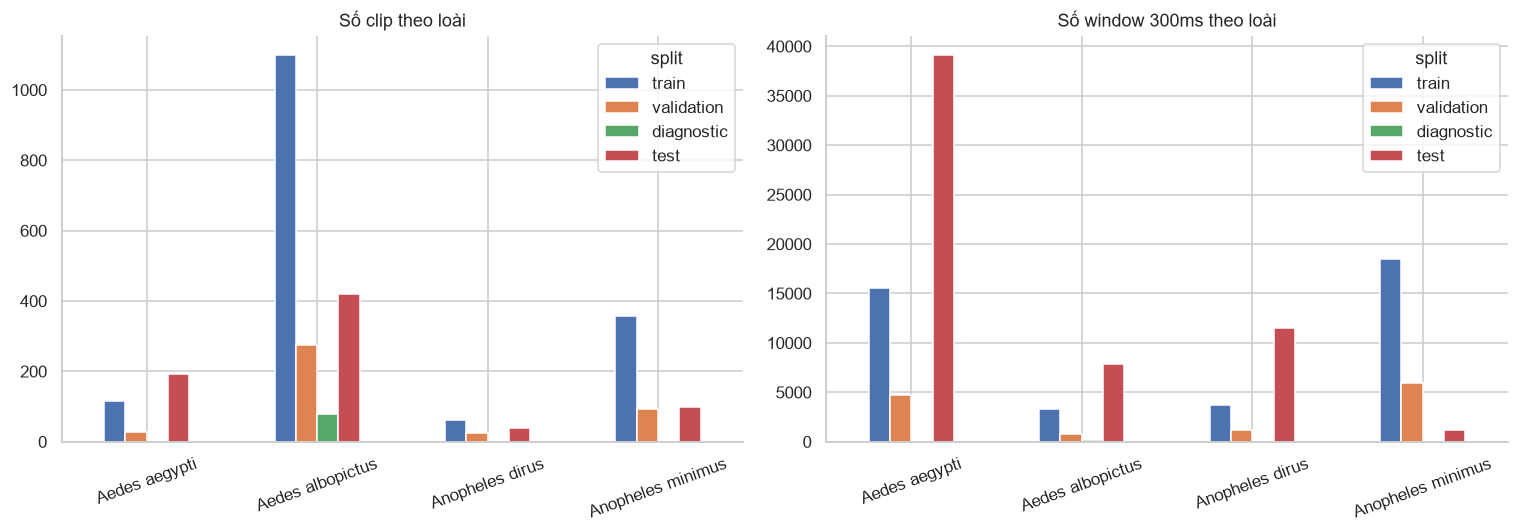

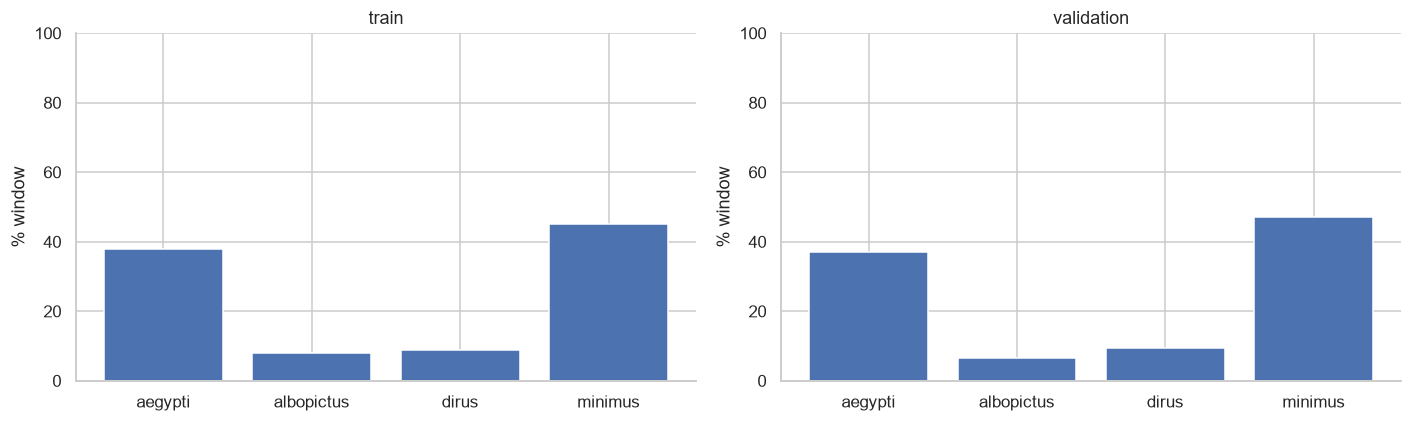

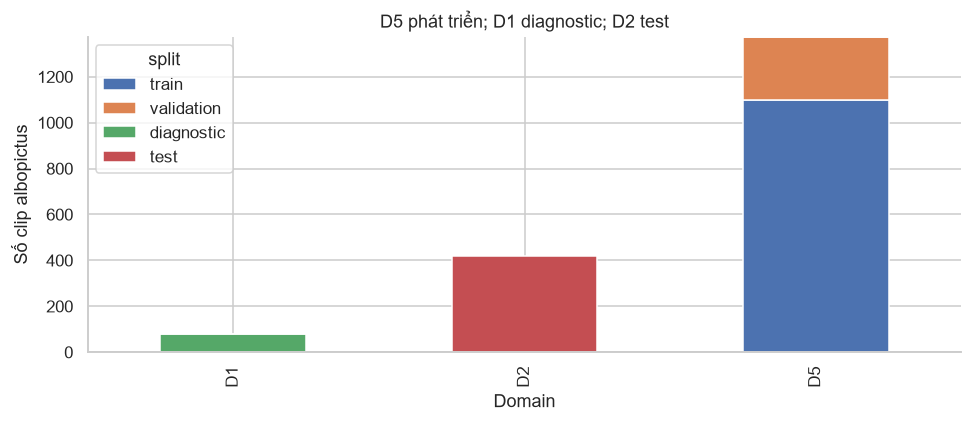

,species,split,clips,eligible_clips,windows,minutes,evidence_groups
0,Aedes aegypti,test,192,192,39113,98.476704,192
1,Aedes aegypti,train,117,95,15592,39.347979,56
2,Aedes aegypti,validation,28,28,4681,11.792460,15
3,Aedes albopictus,diagnostic,79,67,164,0.697894,1
4,Aedes albopictus,test,419,419,7886,21.305088,418
5,Aedes albopictus,train,1099,1099,3297,11.447917,1099
6,Aedes albopictus,validation,275,275,825,2.864583,275
7,Anopheles dirus,test,38,38,11501,28.891362,38
8,Anopheles dirus,train,63,63,3669,9.407533,28
9,Anopheles dirus,validation,24,24,1184,3.053279,8


,species,split,clips,eligible_clips,windows,minutes,evidence_groups,window_share_pct
1,Aedes aegypti,train,117,95,15592,39.347979,56,38.018141
2,Aedes aegypti,validation,28,28,4681,11.792460,15,37.112503
5,Aedes albopictus,train,1099,1099,3297,11.447917,1099,8.039111
6,Aedes albopictus,validation,275,275,825,2.864583,275,6.540871
8,Anopheles dirus,train,63,63,3669,9.407533,28,8.946162
9,Anopheles dirus,validation,24,24,1184,3.053279,8,9.387140
11,Anopheles minimus,train,358,347,18454,47.318642,332,44.996586
12,Anopheles minimus,validation,92,92,5923,15.115927,85,46.959486


In [7]:
verify_cell('visuals')
summary=kept.groupby(['species','split']).agg(clips=('clip_id','size'),eligible_clips=('window_eligible','sum'),windows=('full_windows','sum'),minutes=('processed_seconds',lambda s:s.sum()/60),evidence_groups=('leakage_group','nunique')).reset_index()
table(summary,'split_summary')
coverage=kept.groupby(['species','split','domain','group_basis']).agg(clips=('clip_id','size'),windows=('full_windows','sum'),evidence_groups=('leakage_group','nunique')).reset_index()
table(coverage,'source_domain_coverage')
comparison=parent_clips.loc[parent_clips.status.eq('keep')].groupby(['species','split']).agg(A_v1_clips=('clip_id','size'),A_v1_windows=('full_windows','sum')).reset_index().merge(summary[['species','split','clips','windows']],on=['species','split'],how='outer').fillna(0)
table(comparison,'A_v1_A_v2_comparison')
balance=summary.loc[summary.split.isin(['train','validation'])].copy()
balance['window_share_pct']=100*balance.windows/balance.groupby('split').windows.transform('sum')
table(balance,'training_validation_balance')
fig,axes=plt.subplots(1,2,figsize=(14,5))
for ax,col,title in zip(axes,['clips','windows'],['Số clip theo loài','Số window 300ms theo loài']):
    frame=summary.pivot(index='species',columns='split',values=col).reindex(index=LABEL_NAMES,columns=SPLITS).fillna(0)
    frame.plot.bar(ax=ax);ax.set_title(title);ax.set_xlabel('');ax.tick_params(axis='x',rotation=20)
figure('01_split_counts')
fig,axes=plt.subplots(1,2,figsize=(13,4))
for ax,s in zip(axes,['train','validation']):
    frame=balance.loc[balance.split.eq(s)].set_index('species').reindex(LABEL_NAMES)
    ax.bar([x.split()[-1] for x in LABEL_NAMES],frame.window_share_pct);ax.set_ylabel('% window');ax.set_title(s);ax.set_ylim(0,100)
figure('02_window_balance')
fig,ax=plt.subplots(figsize=(9,4))
alb=kept.loc[kept.label_id.eq(1)].groupby(['domain','split']).size().unstack(fill_value=0).reindex(columns=SPLITS,fill_value=0)
alb.plot.bar(stacked=True,ax=ax);ax.set_ylabel('Số clip albopictus');ax.set_xlabel('Domain');ax.set_title('D5 phát triển; D1 diagnostic; D2 test')
figure('03_albopictus_domains')
display(summary);display(balance)

## 5. Kiểm tra audio D5 và ví dụ window thật
Đọc toàn bộ D5 train/validation để đối chiếu hash WAV và tín hiệu mono 8kHz với A_v1; minh họa một window mỗi loài/split. Không mở audio D1 diagnostic hoặc test. Không diễn giải STFT như xác minh nhãn sinh học.

D5 audio hash: 400 / 1374


D5 audio hash: 800 / 1374


D5 audio hash: 1200 / 1374


D5 audio hash: 1374 / 1374


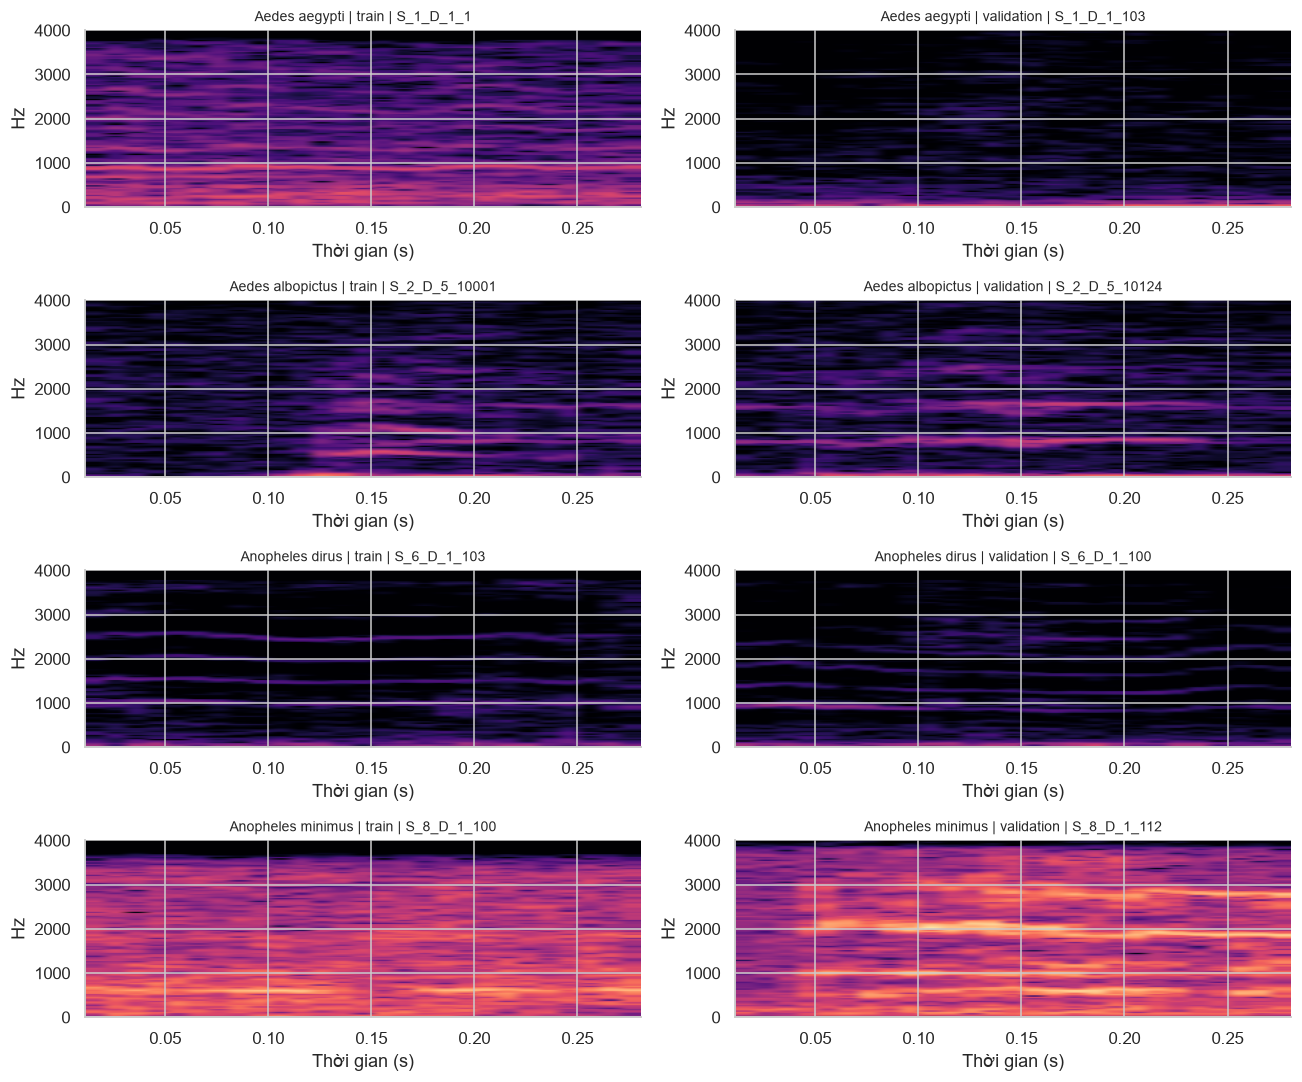

,clip_id,split
0,S_1_D_1_1,train
1,S_1_D_1_103,validation
2,S_2_D_5_10001,train
3,S_2_D_5_10008,train
4,S_2_D_5_10015,train
...,...,...
1375,S_2_D_5_9992,train
1376,S_6_D_1_100,validation
1377,S_6_D_1_103,train
1378,S_8_D_1_100,train


In [8]:
verify_cell('audio')
allowed_ids=set(kept.loc[kept.split.isin(['train','validation']),'clip_id'])
test_ids=set(test_after.clip_id)
audio_accessed=set()
def read_clip(clip_id):
    if clip_id not in allowed_ids:raise ValueError('Chỉ đọc audio train/validation: '+clip_id)
    r=lookup.loc[clip_id]
    p=ROOT/'data/audio/biodcase_A_v1'/PureWindowsPath(str(r.path)).name
    if not p.is_file() and not IS_COLAB:p=Path(r.path)
    assert p.is_file() and sha(p)==r.sha256, 'Raw WAV không khớp A_v1: '+clip_id
    x,sr=sf.read(p,dtype='float64',always_2d=True)
    assert len(x)>0 and np.isfinite(x).all();x=x.mean(axis=1)
    if int(sr)!=SAMPLE_RATE:
        g=gcd(int(sr),SAMPLE_RATE);x=resample_poly(x,SAMPLE_RATE//g,int(sr)//g)
    x=np.asarray(x,dtype='<f4')
    h=hashlib.sha256(f'{SAMPLE_RATE}|1|{len(x)}|'.encode()+x.tobytes()).hexdigest()
    assert h==r.canonical_sha256 and len(x)==int(r.processed_frames),clip_id
    audio_accessed.add(clip_id);return x
for i,clip_id in enumerate(sorted(d5.clip_id),1):
    read_clip(clip_id)
    if i%400==0 or i==len(d5):print('D5 audio hash:',i,'/',len(d5),flush=True)
fig,axes=plt.subplots(4,2,figsize=(12,10))
for label in range(4):
    for j,s in enumerate(['train','validation']):
        row=windows.loc[windows.label_id.eq(label)&windows.split.eq(s)].sort_values(['clip_id','start_sample']).iloc[0]
        x=read_clip(row.clip_id)[int(row.start_sample):int(row.end_sample)]
        assert len(x)==WINDOW_SAMPLES
        axes[label,j].specgram(x,Fs=SAMPLE_RATE,NFFT=256,noverlap=176,cmap='magma',vmin=-110,vmax=-30)
        axes[label,j].set_title(f'{LABEL_NAMES[label]} | {s} | {row.clip_id}',fontsize=9)
        axes[label,j].set_xlabel('Thời gian (s)');axes[label,j].set_ylabel('Hz')
figure('04_window_examples')
try:read_clip(sorted(test_ids)[0]);blocked=False
except ValueError:blocked=True
check('Loader chặn test trước I/O',blocked and not audio_accessed&test_ids)
try:read_clip(sorted(diagnostic_ids)[0]);blocked=False
except ValueError:blocked=True
check('Loader chặn D1 diagnostic trước I/O',blocked and not audio_accessed&diagnostic_ids)
check('Đã xác minh toàn bộ D5 bằng audio thật',set(d5.clip_id)<=audio_accessed)
table(pd.DataFrame([dict(clip_id=i,split=lookup.loc[i,'split']) for i in sorted(audio_accessed)]),'audio_access_log')

## 6. Report, khóa A_v2 và bàn giao B
Report tổng hợp thay đổi, số liệu và giới hạn. Bản khóa liên kết checksum A_v1, source A_v2, manifest mới và các bảng quyết định. B phải khởi tạo model mới, fit lại normalization trên train A_v2, không nhập checkpoint A_v1. C–E phát triển bằng train/validation; F mới đánh giá test khi phương pháp đã chốt. D1 là bộ chẩn đoán đã khảo sát, không phải test mù mới.

In [9]:
verify_cell('report')
limitations=[
    'Albopictus train/validation cùng D5; đây là đánh giá trong cùng domain cho loài này, không phải chứng minh chuyển nguồn.',
    'D5 chỉ gắn với albopictus: model có thể tận dụng đặc điểm nguồn. Chất lượng cao chưa chứng minh chỉ học sinh học loài.',
    'D5 thiếu mapping cá thể/phiên thu và loại cảm biến. Nhóm unverified_clip không chứng nhận độc lập phiên thu; audit gần trùng kế thừa A_v1 không phải tìm kiếm vét cạn.',
    'Albopictus D1 đã được khảo sát trong 05–06, giữ diagnostic riêng và không dùng để chọn cấu hình A_v2.',
    'Test giữ nguyên A_v1 và chứa domain khác; điểm validation tốt không bảo đảm test tốt.',
    'Window có overlap và kế thừa nhãn clip; không xem là mẫu sinh học độc lập hoặc nhãn giới tính đã xác minh.',
    'Chưa có kết quả huấn luyện A_v2 hoặc đánh giá ESP32-S3/INMP441.'
]
table(pd.DataFrame({'limitation':limitations}),'limitations')
settings=dict(protocol=PROTOCOL_VERSION,seed=SEED,validation_group_fraction=VALIDATION_GROUP_FRACTION,sample_rate=SAMPLE_RATE,window_samples=WINDOW_SAMPLES,hop_samples=HOP_SAMPLES,
    split_unit='inherited leakage_group; D5 currently unverified_clip',parent_protocol='A_v1',d5_clips=len(d5),d5_groups=len(groups),validation_groups=len(val_groups),numpy=np.__version__,pandas=pd.__version__,scipy=scipy.__version__,soundfile=sf.__version__)
table(pd.DataFrame([dict(item=k,value=str(v)) for k,v in settings.items()]),'protocol_summary')
for p,value in PROTECTED.items():check('Giữ nguyên '+str(p.relative_to(ROOT)),sha(p)==value)
check('Source cell khớp repo',all(c.metadata.tags[0] in core_cells for c in notebook_source.cells if c.cell_type=='code' and c.metadata.get('tags') and c.metadata.tags[0] not in ('settings','bootstrap','dependencies')))
table(pd.DataFrame(checks),'validation_checks')
freeze_rows=[dict(item=k,value=v) for k,v in settings.items()]
freeze_rows += [dict(item='protocol_version',value=PROTOCOL_VERSION),dict(item='stage_status',value='A_v2 prepared; baseline must be retrained from scratch'),
 dict(item='test_access_policy',value='No test audio/scoring in B-E; D1 diagnostic excluded from development'),
 dict(item='notebook_source_sha256',value=hashlib.sha256('\n'.join(c.source for c in notebook_source.cells).encode()).hexdigest())]
files=dict(clip_manifest=CLIP_PATH,window_manifest=WINDOW_PATH,parent_freeze=PARENT_FREEZE,parent_clip_manifest=PARENT_CLIPS,parent_window_manifest=PARENT_WINDOWS,parent_near_pairs=near_path,
    split_assignments=TABLES/'split_assignments.csv',split_summary=TABLES/'split_summary.csv',protocol_summary=TABLES/'protocol_summary.csv',limitations=TABLES/'limitations.csv',validation_checks=TABLES/'validation_checks.csv')
for key,p in files.items():
    freeze_rows.extend([dict(item=key+'_path',value=p.relative_to(ROOT).as_posix()),dict(item=key+'_sha256',value=sha(p))])
table(pd.DataFrame(freeze_rows),'dataset_freeze')
shutil.copyfile(NOTEBOOK_PATH,OUT/'source_notebook.ipynb')
def frame_html(d):return d.to_html(index=False,border=0,float_format=lambda v:f'{v:,.3f}')
def image_html(name):
    content=base64.b64encode((FIGURES/(name+'.png')).read_bytes()).decode()
    return f'<img src="data:image/png;base64,{content}" alt="{name}">'
sections=['<h1>A_v2 — Albopictus D5 train/validation</h1>',
 '<p>Chuẩn bị dữ liệu hoàn tất; chưa huấn luyện hoặc chấm điểm model A_v2. Không đọc audio test/D1 diagnostic.</p>',
 '<h2>1. Quyết định và phạm vi</h2><p>Giữ QC, pool audio, nhãn, test và các loài khác từ A_v1. Chia D5 theo nhóm trước khi gán window; D1 tách thành diagnostic.</p>',frame_html(pd.DataFrame([dict(item=k,value=str(v)) for k,v in settings.items()])),
 '<h2>2. So sánh A_v1 và A_v2</h2>',frame_html(comparison),
 '<h2>3. Phân bố và imbalance</h2>',frame_html(summary),image_html('01_split_counts'),frame_html(balance),image_html('02_window_balance'),
 '<h2>4. Nguồn và giới hạn độc lập</h2>',frame_html(coverage),image_html('03_albopictus_domains'),'<ul>'+''.join('<li>'+html.escape(s)+'</li>' for s in limitations)+'</ul>',
 '<h2>5. Ví dụ window và kiểm tra</h2>',image_html('04_window_examples'),frame_html(pd.DataFrame(checks)),
 '<h2>6. Bước tiếp theo</h2><p>Chạy smoke rồi full notebook A_v2/04_B_baseline.ipynb. Tám baseline giữ cùng frontend/recipe để lập mốc mới. Model, normalization, cache và kết quả A_v1 không được nhập làm kết quả A_v2.</p>']
css='body{font:16px Arial,sans-serif;max-width:1200px;margin:30px auto;padding:0 20px;line-height:1.6}table{border-collapse:collapse;display:block;overflow-x:auto}td,th{border:1px solid #ddd;padding:6px}img{max-width:100%;height:auto}h1,h2{color:#214c65}'
(OUT/'report.html').write_text('<!doctype html><html lang="vi"><head><meta charset="utf-8"><title>A_v2 preparation</title><style>'+css+'</style></head><body>'+''.join(sections)+'</body></html>',encoding='utf-8')
print('Report:',OUT/'report.html');print('Freeze:',FREEZE_PATH);print('PASS:',len(checks))

Report: D:\VGU-27\Edge AI Rebuild\results\A_v2\preparation\report.html
Freeze: D:\VGU-27\Edge AI Rebuild\results\A_v2\preparation\tables\dataset_freeze.csv
PASS: 34
